# 01 -- Data Exploration (SYNTHETIC DEMO DATA)

**This notebook runs entirely on synthetic, illustrative data** generated by
`fr_power.demo.synthetic.generate_synthetic_market_data` -- not real ENTSO-E
data. It exists so the pipeline can be demonstrated end-to-end without a live
API token. See [`../reports/conclusions.md`](../reports/conclusions.md) for
the honest, qualitative discussion of the *real* French power market, and for
why no genuine quantitative findings about that market are reported without
one.

To run this notebook against real data instead, run `fr-power fetch` (with a
configured `ENTSOE_API_TOKEN`), then load from `data/raw/` via
`fr_power.data.cache.read_cache` in place of `generate_synthetic_market_data`
below.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.demo.synthetic import generate_synthetic_market_data

plt.rcParams["figure.figsize"] = (10, 4)

data = generate_synthetic_market_data(
    start="2019-01-01", end="2022-01-01", seed=42,
    crisis_start="2021-06-01", crisis_end="2021-12-31",
)
day_ahead = data["day_ahead_prices"]["day_ahead_price_eur_mwh"]
wind = data["day_ahead_wind_solar_forecast"]["Wind Onshore"]
solar = data["day_ahead_wind_solar_forecast"]["Solar"]
load = data["day_ahead_load_forecast"]["Forecasted Load"]
nuclear = data["actual_generation_by_type"]["Nuclear"]
intraday = data["intraday"]["intraday_price_eur_mwh"]
spread = intraday - day_ahead

print(f"{len(day_ahead):,} hourly rows, {day_ahead.index.min()} to {day_ahead.index.max()}")

26,304 hourly rows, 2019-01-01 00:00:00+01:00 to 2021-12-31 23:00:00+01:00


## Day-ahead price over time

The shaded band is the generator's illustrative "crisis" regime shift -- a stand-in for the real 2021-2022 energy-crisis / nuclear-outage period (see `reports/conclusions.md`).

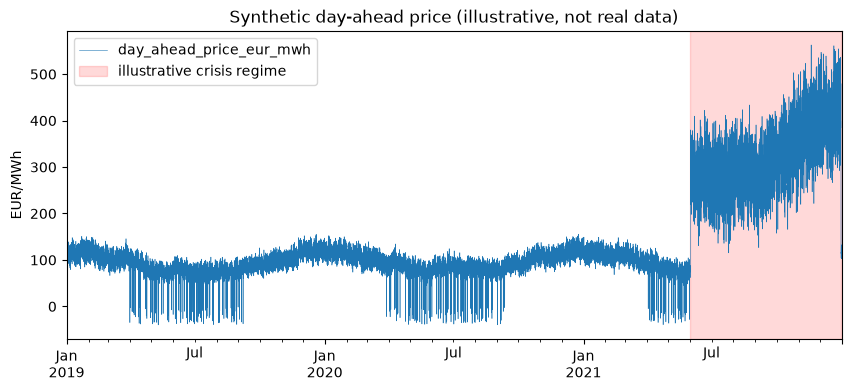

In [2]:
fig, ax = plt.subplots()
day_ahead.plot(ax=ax, linewidth=0.4)
ax.axvspan(
    pd.Timestamp("2021-06-01", tz="Europe/Paris"), pd.Timestamp("2021-12-31", tz="Europe/Paris"),
    color="red", alpha=0.15, label="illustrative crisis regime",
)
ax.set_ylabel("EUR/MWh")
ax.set_title("Synthetic day-ahead price (illustrative, not real data)")
ax.legend()
plt.show()

## Calendar patterns: average price by hour of day and by month

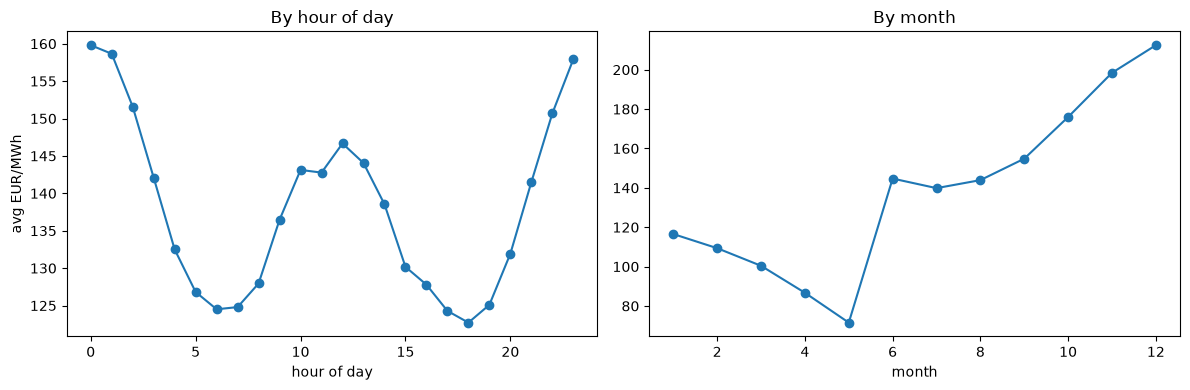

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
day_ahead.groupby(day_ahead.index.hour).mean().plot(ax=axes[0], marker="o")
axes[0].set_xlabel("hour of day"); axes[0].set_ylabel("avg EUR/MWh"); axes[0].set_title("By hour of day")
day_ahead.groupby(day_ahead.index.month).mean().plot(ax=axes[1], marker="o")
axes[1].set_xlabel("month"); axes[1].set_title("By month")
plt.tight_layout()
plt.show()

## Generation mix: nuclear, wind, solar

Note the periodic nuclear maintenance dips and the extra crisis-window shortfall -- both hand-designed into the generator to illustrate the kind of structural pattern a real French dataset would show, not a real outage history.

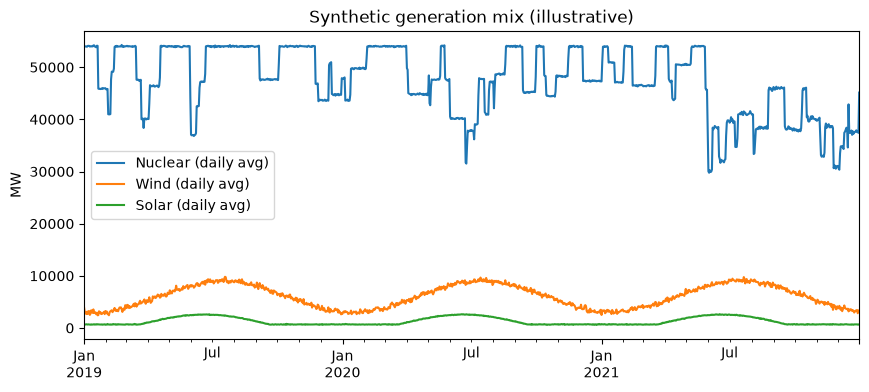

In [4]:
fig, ax = plt.subplots()
nuclear.resample("D").mean().plot(ax=ax, label="Nuclear (daily avg)")
wind.resample("D").mean().plot(ax=ax, label="Wind (daily avg)")
solar.resample("D").mean().plot(ax=ax, label="Solar (daily avg)")
ax.set_ylabel("MW")
ax.set_title("Synthetic generation mix (illustrative)")
ax.legend()
plt.show()

## Residual load vs weather (thermosensitivity)

Residual load = load - wind - solar. The generator ties load to HDD by construction, so this correlation is expected here -- the real-data equivalent of this plot is one of the more informative checks on the actual pipeline.

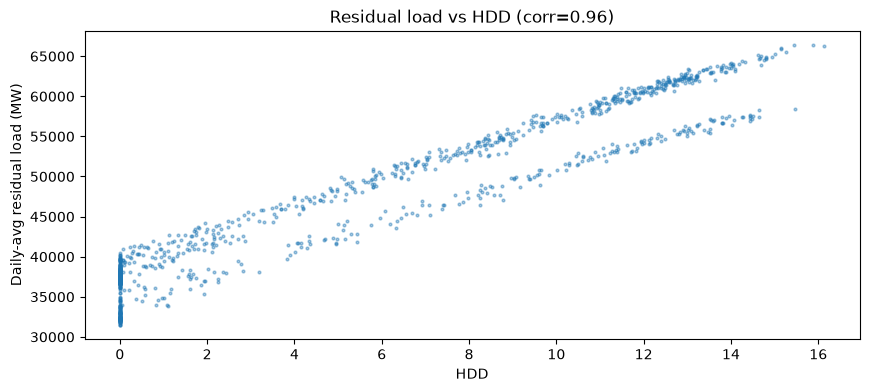

In [5]:
residual_load = load - wind - solar
hdd_daily = data["weather"]["hdd"]
residual_load_daily = residual_load.resample("D").mean()
residual_load_daily.index = residual_load_daily.index.tz_localize(None)
merged = pd.DataFrame({"residual_load_mw": residual_load_daily, "hdd": hdd_daily}).dropna()

fig, ax = plt.subplots()
ax.scatter(merged["hdd"], merged["residual_load_mw"], s=4, alpha=0.4)
ax.set_xlabel("HDD")
ax.set_ylabel("Daily-avg residual load (MW)")
ax.set_title(f"Residual load vs HDD (corr={merged['hdd'].corr(merged['residual_load_mw']):.2f})")
plt.show()

## Intraday-vs-day-ahead spread

The generator builds this spread as a genuinely Ornstein-Uhlenbeck process with a regime shift in its mean during the crisis window -- see notebook 03 for the OU calibration.

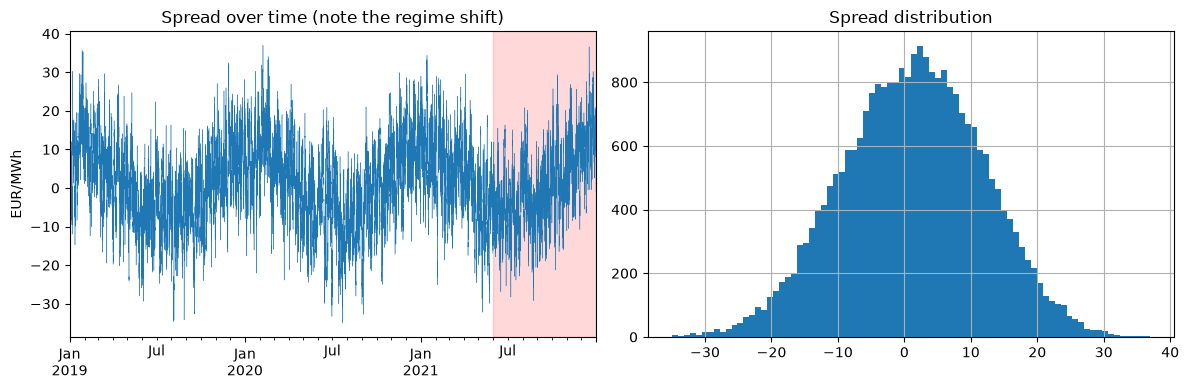

Negative day-ahead price hours: 265 (1.0%)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
spread.plot(ax=axes[0], linewidth=0.3)
axes[0].axvspan(
    pd.Timestamp("2021-06-01", tz="Europe/Paris"), pd.Timestamp("2021-12-31", tz="Europe/Paris"),
    color="red", alpha=0.15,
)
axes[0].set_title("Spread over time (note the regime shift)")
axes[0].set_ylabel("EUR/MWh")
spread.hist(bins=80, ax=axes[1])
axes[1].set_title("Spread distribution")
plt.tight_layout()
plt.show()

print(f"Negative day-ahead price hours: {(day_ahead < 0).sum()} ({(day_ahead < 0).mean():.1%})")